In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
datos=pd.read_excel("C:/Users/usuario/Desktop/datos_inflacion.xlsx")
datos['Fechas'] = pd.to_datetime(datos['Fechas'], dayfirst=True, errors='coerce')
datos.head()

,Fechas,infCOL,infUSA
0,2000-01-31,0.012817,0.002962
1,2000-02-29,0.023077,0.004135
2,2000-03-31,0.016978,0.005882
3,2000-04-30,0.010017,-0.000585
4,2000-05-31,0.005195,0.001755


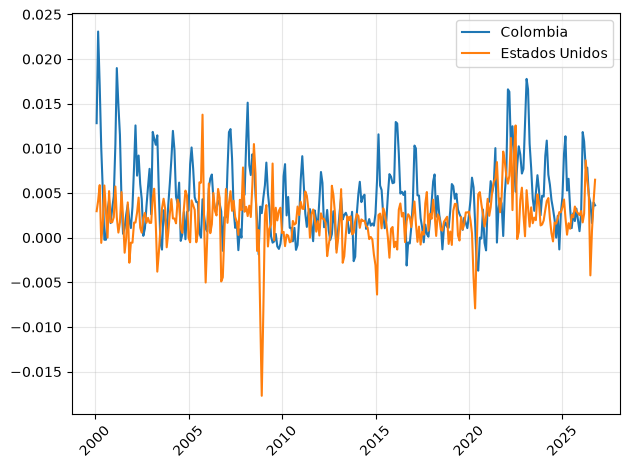

In [3]:
import matplotlib.dates as mdates
plt.plot(datos['Fechas'],datos['infCOL'],label='Colombia')
plt.plot(datos['Fechas'],datos['infUSA'],label='Estados Unidos')
plt.gca().xaxis.set_major_locator(mdates.YearLocator(5))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
plt.show()

In [4]:
from statsmodels.tsa.stattools import adfuller, kpss
adf_col = adfuller(datos['infCOL'].dropna())
print("ADF Colombia - p-valor:", round(adf_col[1], 4))
kpss_col = kpss(datos['infCOL'].dropna(), regression='c', nlags='auto')
print("KPSS Colombia - p-valor:", round(kpss_col[1], 4))
adf_usa = adfuller(datos['infUSA'].dropna())
print("ADF EE.UU. - p-valor:", round(adf_usa[1], 4))
kpss_usa = kpss(datos['infUSA'].dropna(), regression='c', nlags='auto')
print("KPSS EE.UU. - p-valor:", round(kpss_usa[1], 4))

ADF Colombia - p-valor: 0.0062
KPSS Colombia - p-valor: 0.1
ADF EE.UU. - p-valor: 0.0192
KPSS EE.UU. - p-valor: 0.0986


<positron-console-cell-4>:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
<positron-console-cell-4>:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
<positron-console-cell-4>:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this war

In [5]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
def acf_pacf(datos, columna, lags=20):
    serie = datos[columna].dropna()

    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    fig.suptitle(f'ACF y PACF - {columna}', fontsize=14)

    plot_acf(serie, lags=lags, ax=axes[0], alpha=0.05)
    axes[0].set_title('ACF')

    plot_pacf(serie, lags=lags, ax=axes[1], alpha=0.05, method='ywm')
    axes[1].set_title('PACF')

    for ax in axes:
        ax.set_ylim(-1, 1)
        ax.set_xlim(-1, lags + 1)

    plt.tight_layout()
    plt.show()

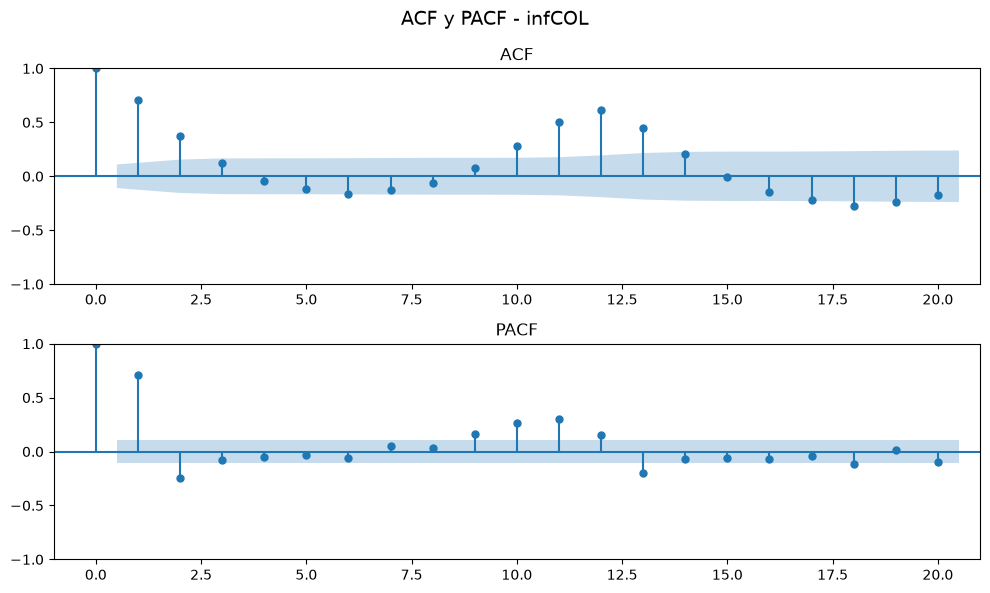

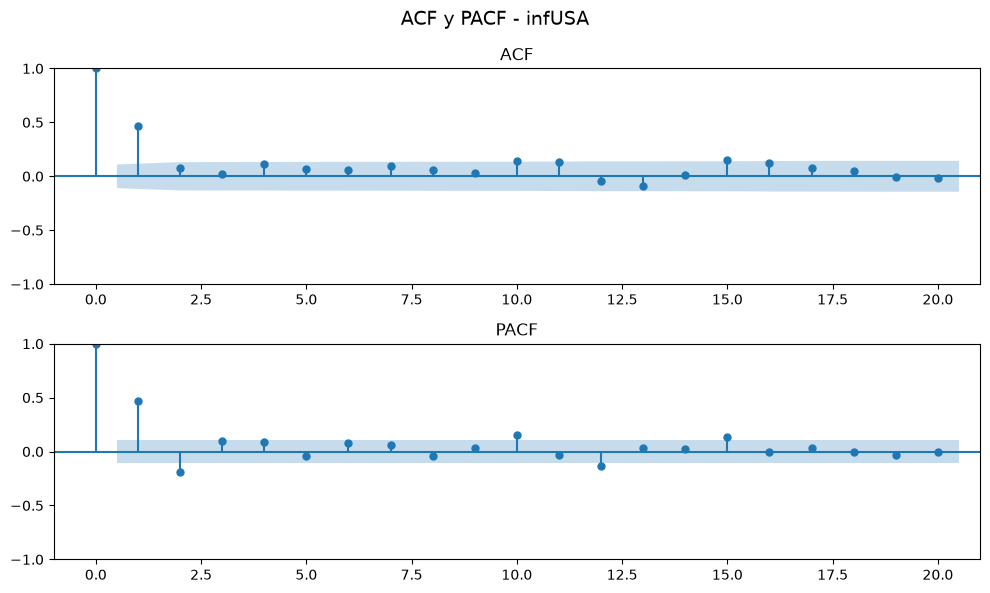

In [6]:
acf_pacf(datos,'infCOL')
acf_pacf(datos,'infUSA')

In [7]:
from statsmodels.tsa.api import VAR
datos_var = datos[['infCOL', 'infUSA']].dropna()
modelo = VAR(datos_var)
resultado = modelo.select_order(maxlags=13)
print(resultado.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -22.65      -22.62   1.459e-10      -22.64
1       -23.56      -23.49   5.850e-11      -23.53
2       -23.63     -23.51*   5.477e-11      -23.58
3       -23.62      -23.45   5.539e-11      -23.55
4       -23.60      -23.39   5.609e-11      -23.52
5       -23.60      -23.34   5.615e-11      -23.50
6       -23.60      -23.28   5.637e-11      -23.47
7       -23.61      -23.25   5.555e-11      -23.47
8       -23.60      -23.19   5.618e-11      -23.44
9       -23.61      -23.15   5.596e-11      -23.42
10      -23.71      -23.20   5.032e-11      -23.51
11      -23.85      -23.29   4.398e-11      -23.62
12      -23.92      -23.31   4.111e-11     -23.67*
13     -23.93*      -23.27  4.062e-11*      -23.67
--------------------------------------------------


In [8]:
modelo = VAR(datos_var)

# VAR con BIC
res_2 = modelo.fit(2)
print(res_2.summary())

# VAR con AIC
res_13 = modelo.fit(13)
print(res_13.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 16, Nov, 2026
Time:                     12:46:25
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -23.5141
Nobs:                     318.000    HQIC:                  -23.5851
Log likelihood:           2865.10    FPE:                5.45251e-11
AIC:                     -23.6324    Det(Omega_mle):     5.28501e-11
--------------------------------------------------------------------
Results for equation infCOL
               coefficient       std. error           t-stat            prob
----------------------------------------------------------------------------
const             0.001446         0.000251            5.757           0.000
L1.infCOL         0.839947         0.053339           15.747           0.000
L1.infUSA         0.082711         0.057963            1.427           0.15

In [9]:
from statsmodels.stats.diagnostic import acorr_ljungbox
print(acorr_ljungbox(res_13.resid['infCOL'], lags=[12], return_df=True))
print(acorr_ljungbox(res_13.resid['infUSA'], lags=[12], return_df=True))

      lb_stat  lb_pvalue
12  12.085271   0.438856
     lb_stat  lb_pvalue
12  1.062346    0.99998


In [10]:
##normalidad
print(res_13.test_normality())

<statsmodels.tsa.vector_ar.hypothesis_test_results.NormalityTestResults object. H_0: data generated by normally-distributed process: reject at 5% significance level. Test statistic: 237.972, critical value: 9.488>, p-value: 0.000>


In [13]:
from statsmodels.stats.diagnostic import het_arch
print(het_arch(res_13.resid['infCOL']))
print(het_arch(res_13.resid['infUSA']))

(np.float64(23.795033086573206), np.float64(0.008163422086420622), 2.4909428037289056, 0.007051259520167007)
(np.float64(48.73061028941308), np.float64(4.563341874299055e-07), 5.6136419230009595, 1.1607525735762749e-07)


C:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [14]:
ultimos_datos = datos_var.values[-13:]
pronostico = res_13.forecast(ultimos_datos, steps=24)

In [15]:
ultima_fecha = pd.to_datetime('2026-09-30')
fechas_futuras = pd.date_range(start=ultima_fecha + pd.offsets.MonthBegin(1), periods=24, freq='MS')
df_pronostico = pd.DataFrame(pronostico, columns=['infCOL', 'infUSA'], index=fechas_futuras)
print(df_pronostico)

              infCOL    infUSA
2026-10-01  0.004911  0.003762
2026-11-01  0.004097  0.002339
2026-12-01  0.005952  0.001266
2027-01-01  0.008502  0.001694
2027-02-01  0.008894  0.003471
2027-03-01  0.007994  0.003144
2027-04-01  0.007115  0.002022
2027-05-01  0.004445  0.001026
2027-06-01  0.003176  0.002898
2027-07-01  0.002936  0.003061
2027-08-01  0.004054  0.002891
2027-09-01  0.004291  0.001535
2027-10-01  0.004037  0.001533
2027-11-01  0.003931  0.001615
2027-12-01  0.005191  0.001821
2028-01-01  0.007133  0.002086
2028-02-01  0.007555  0.002282
2028-03-01  0.006891  0.002086
2028-04-01  0.005614  0.002378
2028-05-01  0.004129  0.002693
2028-06-01  0.003385  0.002384
2028-07-01  0.003204  0.001834
2028-08-01  0.003519  0.001776
2028-09-01  0.003588  0.002042


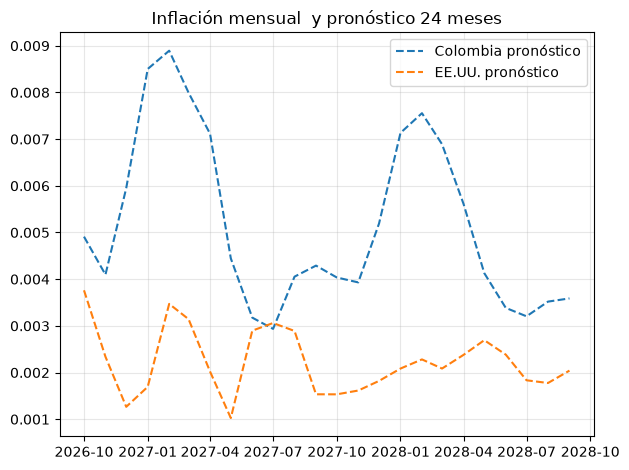

In [16]:
plt.plot(df_pronostico.index, df_pronostico['infCOL'], linestyle='--', label='Colombia pronóstico', color='#1f77b4')
plt.plot(df_pronostico.index, df_pronostico['infUSA'], linestyle='--', label='EE.UU. pronóstico', color='#ff7f0e')
plt.title('Inflación mensual  y pronóstico 24 meses')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
train_df = datos[datos['Fechas'] < '2025-01-01']
real_2025_df = datos[datos['Fechas'] >= '2025-01-01']
train = train_df.set_index('Fechas')[['infCOL', 'infUSA']]
real_2025 = real_2025_df.set_index('Fechas')[['infCOL', 'infUSA']]
modelo_train = VAR(train)
res_train = modelo_train.fit(13)

pronostico_2025 = res_train.forecast(train.values[-13:], steps=12)
fechas_2025 = pd.date_range(start='2025-01-01', periods=12, freq='MS')
df_pron_2025 = pd.DataFrame(pronostico_2025, columns=['infCOL', 'infUSA'], index=fechas_2025)

print(df_pron_2025)

              infCOL    infUSA
2025-01-01  0.007541  0.002891
2025-02-01  0.008361  0.002196
2025-03-01  0.006410  0.002123
2025-04-01  0.005306  0.002162
2025-05-01  0.004320  0.002581
2025-06-01  0.003843  0.002649
2025-07-01  0.003059  0.003065
2025-08-01  0.002253  0.002193
2025-09-01  0.002395  0.002510
2025-10-01  0.001453  0.001872
2025-11-01  0.003232  0.001593
2025-12-01  0.004863  0.001382


C:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


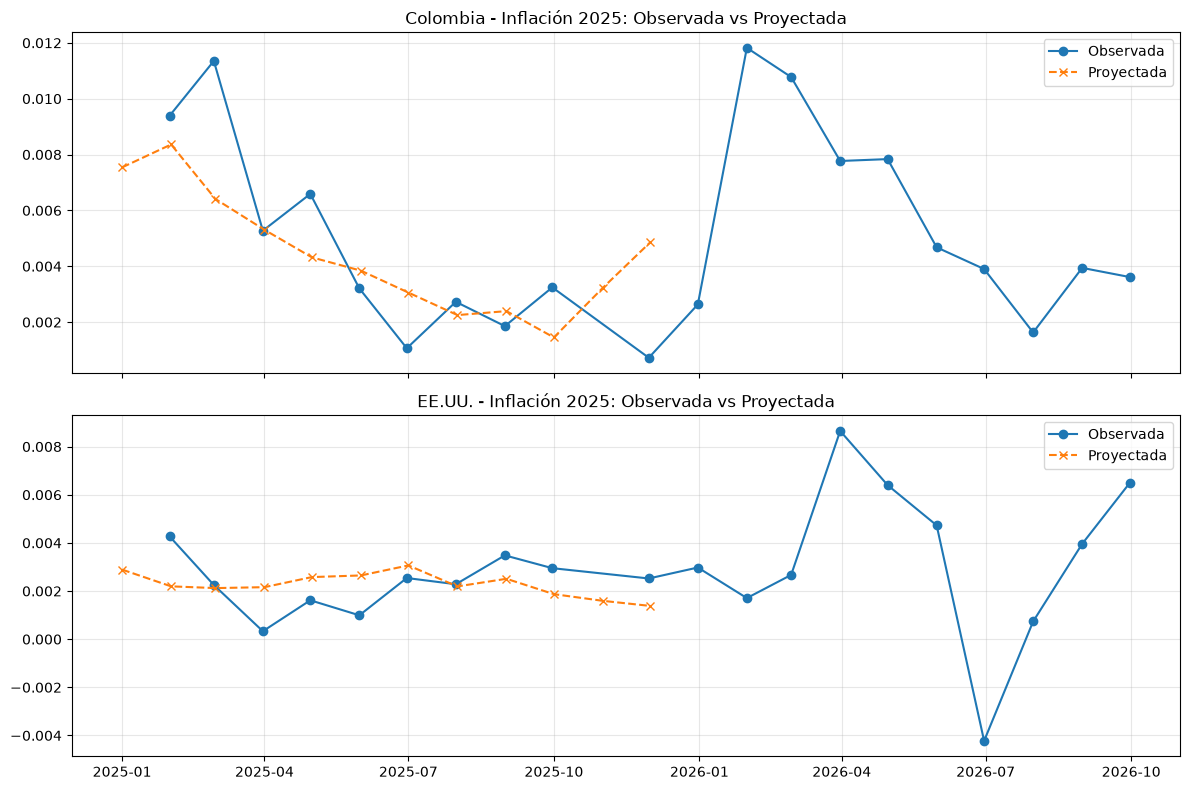

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Colombia
axes[0].plot(real_2025.index, real_2025['infCOL'], label='Observada', marker='o')
axes[0].plot(df_pron_2025.index, df_pron_2025['infCOL'], label='Proyectada', linestyle='--', marker='x')
axes[0].set_title('Colombia - Inflación 2025: Observada vs Proyectada')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# EE.UU.
axes[1].plot(real_2025.index, real_2025['infUSA'], label='Observada', marker='o')
axes[1].plot(df_pron_2025.index, df_pron_2025['infUSA'], label='Proyectada', linestyle='--', marker='x')
axes[1].set_title('EE.UU. - Inflación 2025: Observada vs Proyectada')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import r2_score
import numpy as np
ajustados = res_13.fittedvalues
reales = datos_var.iloc[13:]
r2_col = r2_score(reales['infCOL'], ajustados['infCOL'])
r2_usa = r2_score(reales['infUSA'], ajustados['infUSA'])
print(f"R2 Colombia: {r2_col:.4f}")
print(f"R2 EE.UU.: {r2_usa:.4f}")

R2 Colombia: 0.6984
R2 EE.UU.: 0.3573
